# 05 · Layer sweep
Trains a separate probe on **every** layer's hidden state and compares them. One forward pass already returns all layers, so extraction costs about the same as notebook 03.

Each `data/hidden_states_all_layers/<example_id>.npy` has shape `(num_layers + 1, hidden_dim)`: row 0 is the embedding output, row *i* is block *i* (same indexing as `config.LAYER_INDEX`). Splits match notebook 03, and every layer goes through the same C search as notebook 04. Because val is small, each layer also gets a `cv_auroc`: 5-fold cross-validated AUROC on train+val pooled (folds grouped by question, C chosen by CV).

Already-extracted files are reused, so you can re-run the notebook without the model once extraction has finished.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
%load_ext autoreload
%autoreload 2
from src import config

In [2]:
from src.io_utils import read_jsonl, write_jsonl
from src.hidden_states import extract_hidden_states_all_layers

questions = read_jsonl(config.QUESTIONS_PATH)
labeled = [r for r in read_jsonl(config.LABELED_PATH) if r['model_name'] == config.MODEL_NAME]

missing = [r for r in labeled if not (config.ALL_LAYERS_DIR / f"{r['example_id']}.npy").exists()]
model = tokenizer = None
if missing:
    from src.model_utils import load_model
    model, tokenizer = load_model(config.MODEL_NAME)
records = extract_hidden_states_all_layers(model, tokenizer, labeled, questions,
                                           method=config.TOKEN_POSITION_METHOD)
write_jsonl(config.ALL_LAYERS_DATASET_PATH, records)
print(f'{len(missing)} extracted, {len(records)} total')

/Users/snehvora/Desktop/Projects/Research/hallucination-research/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


All layers / answer_last_token:   0%|          | 0/500 [00:00<?, ?it/s]

All layers / answer_last_token: 100%|██████████| 500/500 [00:00<00:00, 85559.63it/s]

0 extracted, 500 total


In [3]:
from src.probe import load_splits, layer_sweep

splits = load_splits(records)
{s: (X.shape, y.mean().round(3)) for s, (X, y) in splits.items()}

{'train': ((350, 37, 2048), np.float64(0.469)),
 'val': ((75, 37, 2048), np.float64(0.48)),
 'test': ((75, 37, 2048), np.float64(0.427))}

In [4]:
cv_groups = [r['question_id'] for s in ('train', 'val') for r in records if r['dataset_split'] == s]
results, probes = layer_sweep(splits, cv_groups=cv_groups)
pd_cols = ['layer_index', 'C', 'train_auroc', 'val_auroc', 'test_auroc', 'cv_auroc', 'cv_C', 'val_accuracy', 'test_accuracy', 'test_f1']
results[pd_cols].round(3)

Layer sweep:   0%|          | 0/37 [00:00<?, ?it/s]

Layer sweep:   3%|▎         | 1/37 [00:00<00:24,  1.48it/s]

Layer sweep:   5%|▌         | 2/37 [00:01<00:25,  1.36it/s]

Layer sweep:   8%|▊         | 3/37 [00:02<00:25,  1.32it/s]

Layer sweep:  11%|█         | 4/37 [00:03<00:25,  1.30it/s]

Layer sweep:  14%|█▎        | 5/37 [00:03<00:24,  1.29it/s]

... (30 outputs left out)

Layer sweep:  97%|█████████▋| 36/37 [00:26<00:00,  1.45it/s]

Layer sweep: 100%|██████████| 37/37 [00:27<00:00,  1.45it/s]

Layer sweep: 100%|██████████| 37/37 [00:27<00:00,  1.36it/s]

,layer_index,C,train_auroc,val_auroc,test_auroc,cv_auroc,cv_C,val_accuracy,test_accuracy,test_f1
0,0,0.000,0.532,0.490,0.504,0.514,0.100,0.507,0.573,0.059
1,1,1.000,1.000,0.511,0.569,0.558,0.001,0.533,0.560,0.459
2,2,0.100,1.000,0.538,0.555,0.547,0.000,0.507,0.547,0.433
3,3,1.000,1.000,0.581,0.539,0.571,0.000,0.573,0.507,0.413
4,4,0.000,0.712,0.620,0.635,0.623,0.000,0.600,0.627,0.417
5,5,0.100,1.000,0.663,0.625,0.621,0.000,0.653,0.653,0.606
6,6,1.000,1.000,0.647,0.685,0.630,0.001,0.600,0.653,0.594
7,7,0.010,0.988,0.626,0.642,0.631,0.000,0.573,0.627,0.576
8,8,0.000,0.773,0.697,0.670,0.635,0.001,0.667,0.653,0.581
9,9,0.000,0.771,0.685,0.612,0.644,0.001,0.613,0.627,0.533


In [5]:
import json, joblib

tag = f"{config.MODEL_NAME.split('/')[-1]}_{config.TOKEN_POSITION_METHOD}"
best = results.loc[results['val_auroc'].idxmax()]
best_layer = int(best['layer_index'])
print(f"Best layer by val AUROC: {best_layer} (val {best['val_auroc']:.3f}, test {best['test_auroc']:.3f})")
best_cv_layer = int(results.loc[results['cv_auroc'].idxmax(), 'layer_index'])
print(f"Best layer by {config.CV_FOLDS}-fold CV AUROC: {best_cv_layer} (cv {results.loc[best_cv_layer, 'cv_auroc']:.3f})")
base = results.loc[config.LAYER_INDEX]
print(f"Layer {config.LAYER_INDEX} (single-layer baseline): "
      f"val {base['val_auroc']:.3f}, test {base['test_auroc']:.3f}, cv {base['cv_auroc']:.3f}")

config.MODELS_DIR.mkdir(exist_ok=True); config.RESULTS_DIR.mkdir(exist_ok=True)
results.to_csv(config.RESULTS_DIR / f'layer_sweep_{tag}.csv', index=False)
summary = {'model_name': config.MODEL_NAME, 'token_position_method': config.TOKEN_POSITION_METHOD,
           'selection': 'max val_auroc', 'best_layer': best_layer,
           'cv_folds': config.CV_FOLDS, 'best_layer_cv': best_cv_layer, 'C_grid': config.PROBE_C_GRID, 'layers': results.to_dict(orient='records')}
(config.RESULTS_DIR / f'layer_sweep_{tag}.json').write_text(json.dumps(summary, indent=2))
joblib.dump(probes[best_layer], config.MODELS_DIR / f"probe_{config.MODEL_NAME.split('/')[-1]}_L{best_layer}_{config.TOKEN_POSITION_METHOD}_sweep.joblib")

Best layer by val AUROC: 8 (val 0.697, test 0.670)
Best layer by 5-fold CV AUROC: 33 (cv 0.697)
Layer 16 (single-layer baseline): val 0.630, test 0.581, cv 0.651


['/Users/snehvora/Desktop/Projects/Research/hallucination-research/models/probe_Qwen2.5-3B-Instruct_L8_answer_last_token_sweep.joblib']

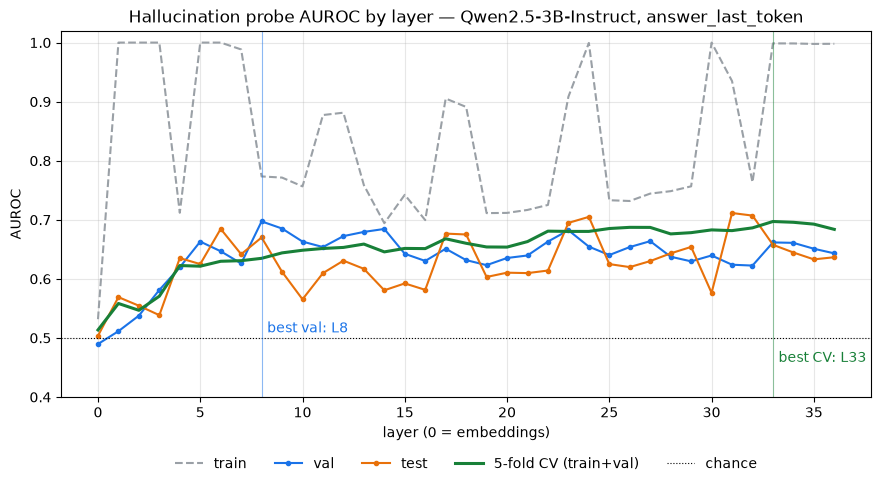

In [6]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(results['layer_index'], results['train_auroc'], color='#9aa0a6', ls='--', label='train')
ax.plot(results['layer_index'], results['val_auroc'], color='#1a73e8', marker='o', ms=3, label='val')
ax.plot(results['layer_index'], results['test_auroc'], color='#e8710a', marker='o', ms=3, label='test')
ax.plot(results['layer_index'], results['cv_auroc'], color='#188038', lw=2.2, label=f'{config.CV_FOLDS}-fold CV (train+val)')
ax.axhline(0.5, color='black', lw=0.8, ls=':', label='chance')
ax.axvline(best_layer, color='#1a73e8', lw=0.8, alpha=0.5)
ax.annotate(f'best val: L{best_layer}', (best_layer, 0.5), xytext=(4, 4), textcoords='offset points', color='#1a73e8')
ax.axvline(best_cv_layer, color='#188038', lw=0.8, alpha=0.5)
ax.annotate(f'best CV: L{best_cv_layer}', (best_cv_layer, 0.45), xytext=(4, 4), textcoords='offset points', color='#188038')
ax.set_xlabel('layer (0 = embeddings)'); ax.set_ylabel('AUROC')
ax.set_title(f"Hallucination probe AUROC by layer — {config.MODEL_NAME.split('/')[-1]}, {config.TOKEN_POSITION_METHOD}")
ax.set_ylim(0.4, 1.02); ax.grid(alpha=0.3)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.13), ncol=5, frameon=False)
fig.tight_layout()
fig.savefig(config.RESULTS_DIR / f'layer_sweep_{tag}.png', dpi=150)
plt.show()

Val and test hold ~75 questions each, so a single layer's val or test AUROC moves by several points from noise alone. The CV curve averages over all ~425 train+val questions and is the steadier guide; read its overall shape rather than trusting the single top layer.